# Liver Cirrhosis Survival Prediction
## Notebook 01 — Load & Explore

**Target:** `Status` (C = Alive/censored · D = Deceased · CL = Liver transplant)  
**Approach:** Use Stage + lab values as features to predict survival outcome  
**Output:** Understanding of data — shapes, types, distributions, class balance, and the clinical relationship between Stage and survival

---
> **Notebook dependencies:** This notebook only needs `data/train.csv` and `data/test.csv`.  
> It does not depend on any other notebook.  
> Run all cells top to bottom in order.


In [ ]:
# ── Mount Google Drive (always mount to /content/drive) ──────
from google.colab import drive
drive.mount('/content/drive')

# ── Navigate to your project folder ──────────────────────────
import os
os.chdir('/content/drive/MyDrive/Maria_Sagwa/Cirrhosis_Project')

# ── Verify you are in the right place ────────────────────────
print("Working directory:", os.getcwd())
print("Files found:", os.listdir('.'))

: 

### Cell 1.0 — Imports & display settings

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

print("Libraries loaded ✓")


Libraries loaded ✓


### Cell 1.1 — Load datasets

In [ ]:
train = pd.read_csv('/content/drive/MyDrive/Maria_Sagwa/Cirrhosis_Project/train.csv')
test  = pd.read_csv('/content/drive/MyDrive/Maria_Sagwa/Cirrhosis_Project/test.csv')

print("=" * 65)
print("1.1  DATASETS LOADED")
print("=" * 65)
print(f"  Train : {train.shape[0]:,} rows  ×  {train.shape[1]} columns")
print(f"  Test  : {test.shape[0]:,} rows  ×  {test.shape[1]} columns")
print(f"\n  Columns ({len(train.columns)}):")
for i, col in enumerate(train.columns, 1):
    print(f"    {i:>2}. {col}")


1.1  DATASETS LOADED
  Train : 7,905 rows  ×  20 columns
  Test  : 5,271 rows  ×  19 columns

  Columns (20):
     1. id
     2. N_Days
     3. Drug
     4. Age
     5. Sex
     6. Ascites
     7. Hepatomegaly
     8. Spiders
     9. Edema
    10. Bilirubin
    11. Cholesterol
    12. Albumin
    13. Copper
    14. Alk_Phos
    15. SGOT
    16. Tryglicerides
    17. Platelets
    18. Prothrombin
    19. Stage
    20. Status


### Cell 1.2 — DataFrame info

In [ ]:
print("=" * 65)
print("1.2  DATAFRAME INFO")
print("=" * 65)
train.info()


1.2  DATAFRAME INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7905 entries, 0 to 7904
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             7905 non-null   int64  
 1   N_Days         7905 non-null   int64  
 2   Drug           7905 non-null   object 
 3   Age            7905 non-null   int64  
 4   Sex            7905 non-null   object 
 5   Ascites        7905 non-null   object 
 6   Hepatomegaly   7905 non-null   object 
 7   Spiders        7905 non-null   object 
 8   Edema          7905 non-null   object 
 9   Bilirubin      7905 non-null   float64
 10  Cholesterol    7905 non-null   float64
 11  Albumin        7905 non-null   float64
 12  Copper         7905 non-null   float64
 13  Alk_Phos       7905 non-null   float64
 14  SGOT           7905 non-null   float64
 15  Tryglicerides  7905 non-null   float64
 16  Platelets      7905 non-null   float64
 17  Prothrombin    7905 non-null   f

### Cell 1.3 — Data types per column

In [ ]:
print("=" * 65)
print("1.3  DATA TYPES")
print("=" * 65)
dtype_df = pd.DataFrame({
    'Column'  : train.dtypes.index,
    'Dtype'   : train.dtypes.values.astype(str),
    'Example' : [str(train[c].dropna().iloc[0]) for c in train.columns]
})
print

1.3  DATA TYPES


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

### Cell 1.4 — Missing values

In [ ]:
print("=" * 65)
print("1.4  MISSING VALUES")
print("=" * 65)
miss_train = train.isnull().sum()
miss_test  = test.isnull().sum()

print(f"  Train — total missing: {miss_train.sum()}", "✓ None" if miss_train.sum() == 0 else "")
print(f"  Test  — total missing: {miss_test.sum()}",  "✓ None" if miss_test.sum() == 0 else "")

if miss_train.sum() > 0:
    print("\n  Missing by column (train):")
    print(miss_train[miss_train > 0])


1.4  MISSING VALUES
  Train — total missing: 0 ✓ None
  Test  — total missing: 0 ✓ None


### Cell 1.5 — Descriptive statistics

In [ ]:
print("=" * 65)
print("1.5  DESCRIPTIVE STATISTICS (numeric columns)")
print("=" * 65)
print(train.describe().round(2).to_string())


1.5  DESCRIPTIVE STATISTICS (numeric columns)
            id   N_Days       Age  Bilirubin  Cholesterol  Albumin  Copper  Alk_Phos     SGOT  Tryglicerides  Platelets  Prothrombin    Stage
count  7905.00  7905.00   7905.00    7905.00      7905.00  7905.00  7905.0   7905.00  7905.00        7905.00    7905.00      7905.00  7905.00
mean   3952.00  2030.17  18373.15       2.59       350.56     3.55    83.9   1816.75   114.60         115.34     265.23        10.63     3.03
std    2282.12  1094.23   3679.96       3.81       195.38     0.35    75.9   1903.75    48.79          52.53      87.47         0.78     0.87
min       0.00    41.00   9598.00       0.30       120.00     1.96     4.0    289.00    26.35          33.00      62.00         9.00     1.00
25%    1976.00  1230.00  15574.00       0.70       248.00     3.35    39.0    834.00    75.95          84.00     211.00        10.00     2.00
50%    3952.00  1831.00  18713.00       1.10       298.00     3.58    63.0   1181.00   108.50         

### Cell 1.6 — Target distribution (Status)

In [ ]:
print("=" * 65)
print("1.6  TARGET DISTRIBUTION  —  Status")
print("=" * 65)
status_map_display = {
    'C' : 'Alive / censored',
    'D' : 'Deceased',
    'CL': 'Liver transplant'
}
for code, label in status_map_display.items():
    n   = (train['Status'] == code).sum()
    pct = n / len(train) * 100
    bar = '█' * int(pct / 2)
    print(f"  {code:2} ({label:20})  {n:5,}  ({pct:5.1f}%)  {bar}")

print()
print("  NOTE: CL (transplant) is only 3.5% — class imbalance.")


1.6  TARGET DISTRIBUTION  —  Status
  C  (Alive / censored    )  4,965  ( 62.8%)  ███████████████████████████████
  D  (Deceased            )  2,665  ( 33.7%)  ████████████████
  CL (Liver transplant    )    275  (  3.5%)  █

  NOTE: CL (transplant) is only 3.5% — class imbalance.


### Cell 1.7 — Stage distribution

In [ ]:
print("=" * 65)
print("1.7  STAGE DISTRIBUTION")
print("=" * 65)
stage_labels = {1: 'Early', 2: 'Moderate', 3: 'Advanced', 4: 'End-stage'}
for stage in sorted(train['Stage'].dropna().unique()):
    n   = (train['Stage'] == stage).sum()
    pct = n / len(train) * 100
    bar = '█' * int(pct / 2)
    print(f"  Stage {int(stage)} ({stage_labels[int(stage)]:10})  {n:5,}  ({pct:5.1f}%)  {bar}")


1.7  STAGE DISTRIBUTION
  Stage 1 (Early     )    397  (  5.0%)  ██
  Stage 2 (Moderate  )  1,652  ( 20.9%)  ██████████
  Stage 3 (Advanced  )  3,153  ( 39.9%)  ███████████████████
  Stage 4 (End-stage )  2,703  ( 34.2%)  █████████████████


### Cell 1.8 — Survival rate by Stage

This cross-tab is the core clinical motivation for using Stage as a feature.  
Stage alone separates survival probability significantly.


In [ ]:
print("=" * 65)
print("1.8  SURVIVAL RATE BY STAGE  (clinical relationship)")
print("=" * 65)

stage_labels = {1: 'Early', 2: 'Moderate', 3: 'Advanced', 4: 'End-stage'}

cross = pd.crosstab(
    train['Stage'],
    train['Status'],
    normalize='index'
).mul(100).round(1)

col_order = [c for c in ['C', 'CL', 'D'] if c in cross.columns]
cross = cross[col_order]
cross.index = [f"Stage {int(s)} ({stage_labels[int(s)]})" for s in cross.index]
cross.columns = ['Alive / censored %', 'Transplant %', 'Deceased %']
print(cross.to_string())

print()
print("  Key insight:")
print("  · Stage 1 → 88.4% alive,  9.8% deceased")
print("  · Stage 4 → 37.8% alive, 58.2% deceased")
print("  · A 6× increase in mortality from Stage 1 to Stage 4")
print("  · Stage is a strong predictive signal for survival")


1.8  SURVIVAL RATE BY STAGE  (clinical relationship)
                     Alive / censored %  Transplant %  Deceased %
Stage 1 (Early)                    88.4           1.8         9.8
Stage 2 (Moderate)                 78.3           2.8        18.9
Stage 3 (Advanced)                 72.9           3.6        23.5
Stage 4 (End-stage)                37.8           4.0        58.2

  Key insight:
  · Stage 1 → 88.4% alive,  9.8% deceased
  · Stage 4 → 37.8% alive, 58.2% deceased
  · A 6× increase in mortality from Stage 1 to Stage 4
  · Stage is a strong predictive signal for survival


### Cell 1.9 — Categorical column unique values

In [ ]:
print("=" * 65)
print("1.9  CATEGORICAL COLUMNS — UNIQUE VALUES")
print("=" * 65)
cat_cols = [c for c in train.columns if train[c].dtype == 'object' or str(train[c].dtype) == 'str']
for col in cat_cols:
    vals = train[col].value_counts().to_dict()
    print(f"  {col:15}  {vals}")

print()



1.9  CATEGORICAL COLUMNS — UNIQUE VALUES
  Drug             {'Placebo': 4010, 'D-penicillamine': 3895}
  Sex              {'F': 7336, 'M': 569}
  Ascites          {'N': 7525, 'Y': 380}
  Hepatomegaly     {'Y': 4042, 'N': 3863}
  Spiders          {'N': 5966, 'Y': 1939}
  Edema            {'N': 7161, 'S': 399, 'Y': 345}
  Status           {'C': 4965, 'D': 2665, 'CL': 275}



### Cell 1.10 — Age column (stored in days)

In [ ]:
print("=" * 65)
print("1.10  AGE COLUMN  (stored in days — needs conversion)")
print("=" * 65)
print(f"  Min : {train['Age'].min():,} days  =  {train['Age'].min()/365.25:.1f} years")
print(f"  Max : {train['Age'].max():,} days  =  {train['Age'].max()/365.25:.1f} years")
print(f"  Mean: {train['Age'].mean():,.0f} days  =  {train['Age'].mean()/365.25:.1f} years")
print()


1.10  AGE COLUMN  (stored in days — needs conversion)
  Min : 9,598 days  =  26.3 years
  Max : 28,650 days  =  78.4 years
  Mean: 18,373 days  =  50.3 years



### Cell 1.11 — N_Days (data leakage risk)

In [ ]:
print("=" * 65)
print("1.11  N_DAYS — DATA LEAKAGE RISK")
print("=" * 65)
print(f"  Range: {train['N_Days'].min()} – {train['N_Days'].max()} days")
print()
print("  What is N_Days?")
print("  The number of days a patient was followed in the clinical study.")
print()
print("  Why is it a problem?")
print("  It is NOT a clinical measurement available at the time of diagnosis.")
print("  A real patient walking into a clinic has no N_Days value.")
print("  A patient who died quickly will have a low N_Days.")
print("  Including it would leak outcome information into the features")
print("  and give artificially high accuracy that would not hold in practice.")
print()


1.11  N_DAYS — DATA LEAKAGE RISK
  Range: 41 – 4795 days

  What is N_Days?
  The number of days a patient was followed in the clinical study.

  Why is it a problem?
  It is NOT a clinical measurement available at the time of diagnosis.
  A real patient walking into a clinic has no N_Days value.
  A patient who died quickly will have a low N_Days.
  Including it would leak outcome information into the features
  and give artificially high accuracy that would not hold in practice.



### Cell 1.12 — Visualisation: Target and Stage distributions

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/01_target_stage_distribution.png'

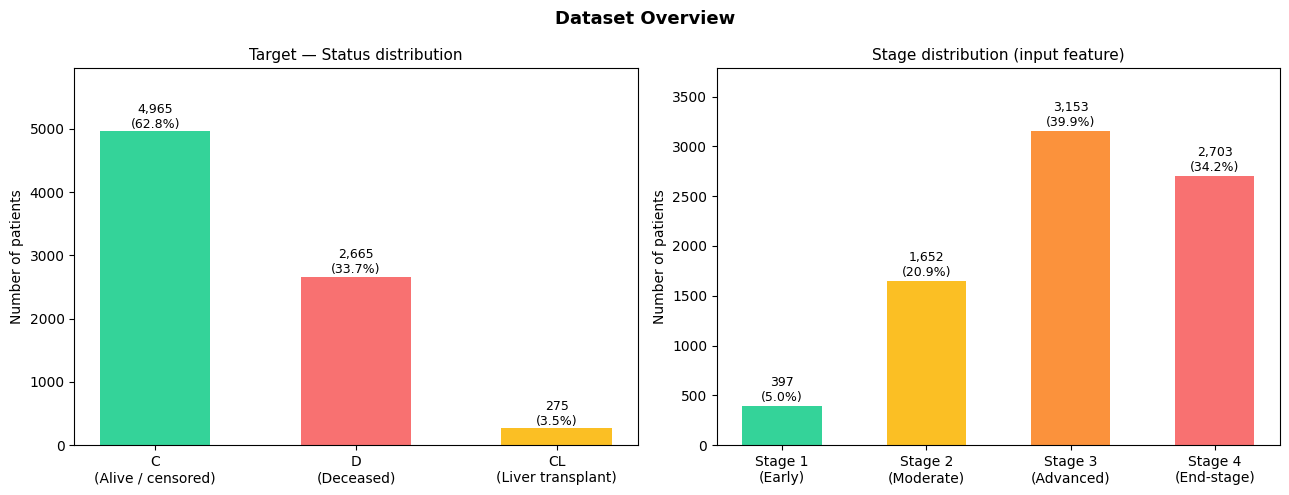

In [ ]:
stage_labels = {1: 'Early', 2: 'Moderate', 3: 'Advanced', 4: 'End-stage'}
status_map_display = {'C': 'Alive / censored', 'D': 'Deceased', 'CL': 'Liver transplant'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Dataset Overview', fontsize=13, fontweight='bold')

# Status
status_counts = train['Status'].value_counts()
colors_status = {'C': '#34d399', 'CL': '#fbbf24', 'D': '#f87171'}
xlabels_status = [f"{c}\n({status_map_display[c]})" for c in status_counts.index]
axes[0].bar(xlabels_status, status_counts.values,
            color=[colors_status[c] for c in status_counts.index],
            edgecolor='none', width=0.55)
axes[0].set_title('Target — Status distribution', fontsize=11)
axes[0].set_ylabel('Number of patients')
axes[0].set_ylim(0, status_counts.max() * 1.2)
for i, (s, n) in enumerate(status_counts.items()):
    axes[0].text(i, n + 50, f'{n:,}\n({n/len(train)*100:.1f}%)',
                 ha='center', fontsize=9)

# Stage
stage_counts  = train['Stage'].value_counts().sort_index()
colors_stage  = {1.0:'#34d399', 2.0:'#fbbf24', 3.0:'#fb923c', 4.0:'#f87171'}
xlabels_stage = [f"Stage {int(s)}\n({stage_labels[int(s)]})" for s in stage_counts.index]
axes[1].bar(xlabels_stage, stage_counts.values,
            color=[colors_stage[s] for s in stage_counts.index],
            edgecolor='none', width=0.55)
axes[1].set_title('Stage distribution (input feature)', fontsize=11)
axes[1].set_ylabel('Number of patients')
axes[1].set_ylim(0, stage_counts.max() * 1.2)
for i, (s, n) in enumerate(stage_counts.items()):
    axes[1].text(i, n + 50, f'{n:,}\n({n/len(train)*100:.1f}%)',
                 ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('outputs/01_target_stage_distribution.png', dpi=130, bbox_inches='tight')
plt.show()


### Cell 1.13 — Visualisation: Survival outcome by Stage (stacked bar)

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/01_survival_by_stage.png'

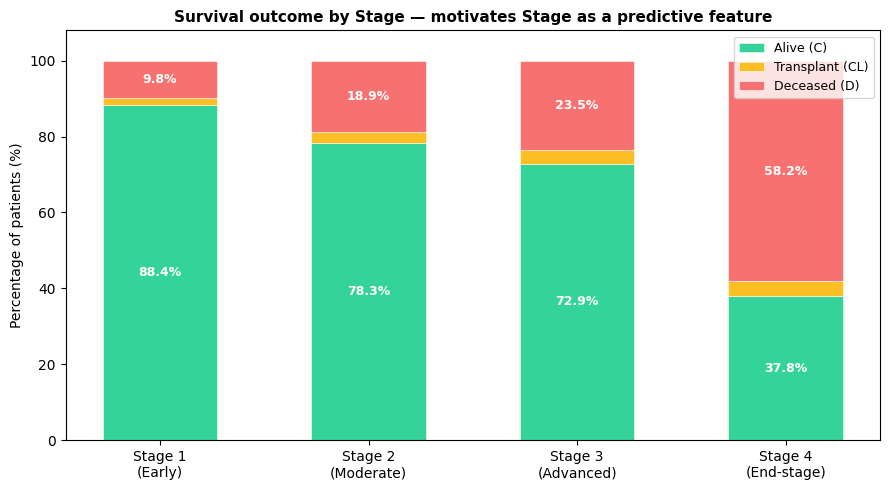

In [ ]:
stage_labels = {1: 'Early', 2: 'Moderate', 3: 'Advanced', 4: 'End-stage'}

fig, ax = plt.subplots(figsize=(9, 5))
cross_pct = pd.crosstab(train['Stage'], train['Status'], normalize='index').mul(100)
col_order  = [c for c in ['C', 'CL', 'D'] if c in cross_pct.columns]
cross_pct  = cross_pct[col_order]

color_map = {'C': '#34d399', 'CL': '#fbbf24', 'D': '#f87171'}
label_map = {'C': 'Alive (C)', 'CL': 'Transplant (CL)', 'D': 'Deceased (D)'}
x      = np.arange(len(cross_pct))
bottom = np.zeros(len(cross_pct))

for col in col_order:
    vals = cross_pct[col].values
    ax.bar(x, vals, bottom=bottom, color=color_map[col],
           label=label_map[col], edgecolor='white', linewidth=0.4, width=0.55)
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 4:
            ax.text(i, b + v/2, f'{v:.1f}%', ha='center', va='center',
                    fontsize=9, color='white', fontweight='bold')
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels([f"Stage {int(s)}\n({stage_labels[int(s)]})"
                    for s in cross_pct.index], fontsize=10)
ax.set_ylabel('Percentage of patients (%)')
ax.set_title('Survival outcome by Stage — motivates Stage as a predictive feature',
             fontsize=11, fontweight='bold')
ax.set_ylim(0, 108)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig('outputs/01_survival_by_stage.png', dpi=130, bbox_inches='tight')
plt.show()


### Cell 1.14 — Visualisation: Numeric feature distributions

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/01_feature_distributions.png'

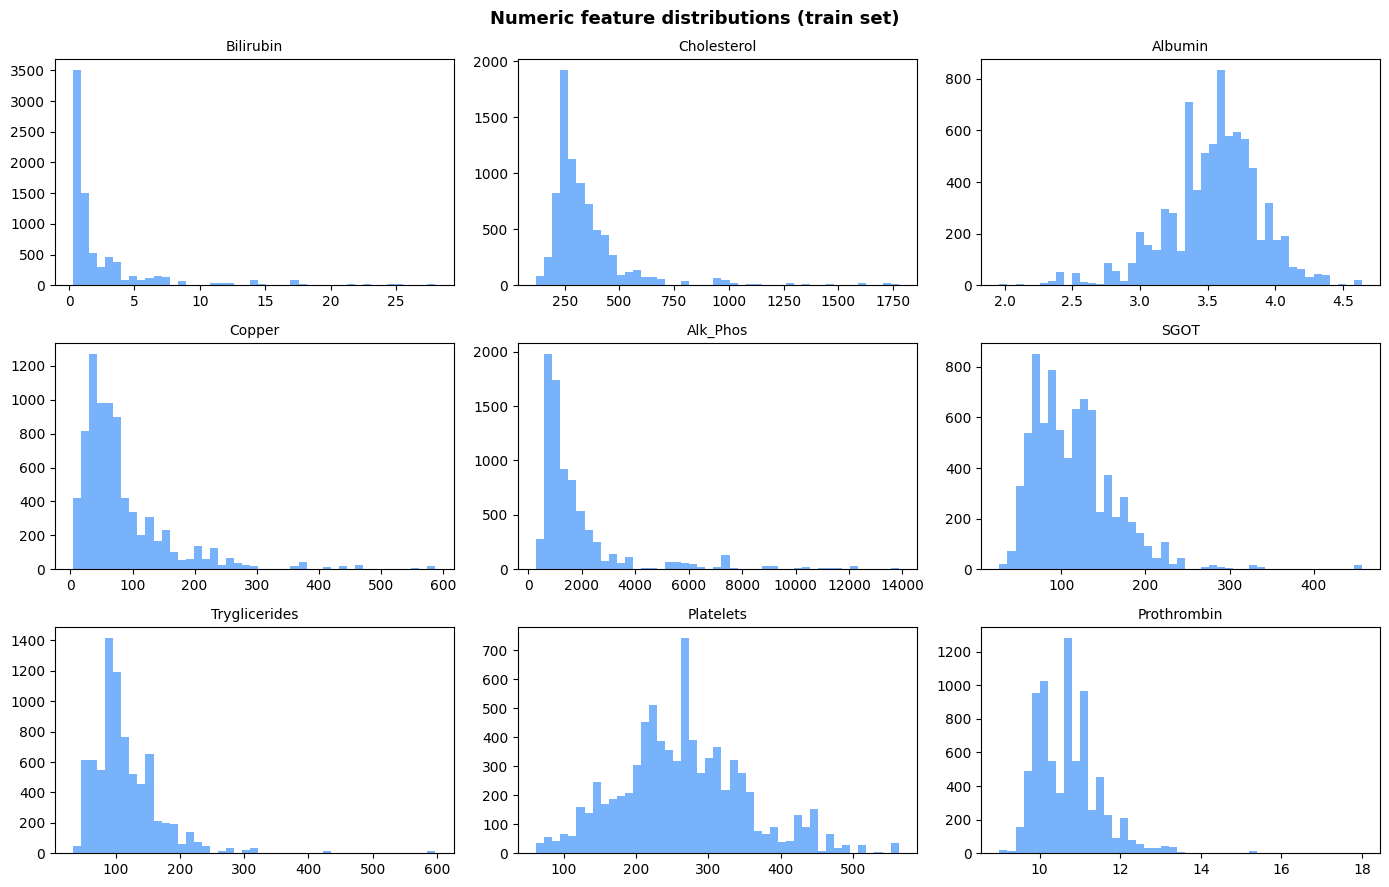

In [ ]:
num_cols = ['Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos',
            'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']

fig, axes = plt.subplots(3, 3, figsize=(14, 9))
fig.suptitle('Numeric feature distributions (train set)', fontsize=13, fontweight='bold')

for ax, col in zip(axes.flatten(), num_cols):
    ax.hist(train[col].dropna(), bins=45, color='#60a5fa',
            edgecolor='none', alpha=0.85)
    ax.set_title(col, fontsize=10)

plt.tight_layout()
plt.savefig('outputs/01_feature_distributions.png', dpi=130, bbox_inches='tight')
plt.show()


### Cell 1.15 — Visualisation: Patient counts by Stage and Status

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/01_counts_by_stage_status.png'

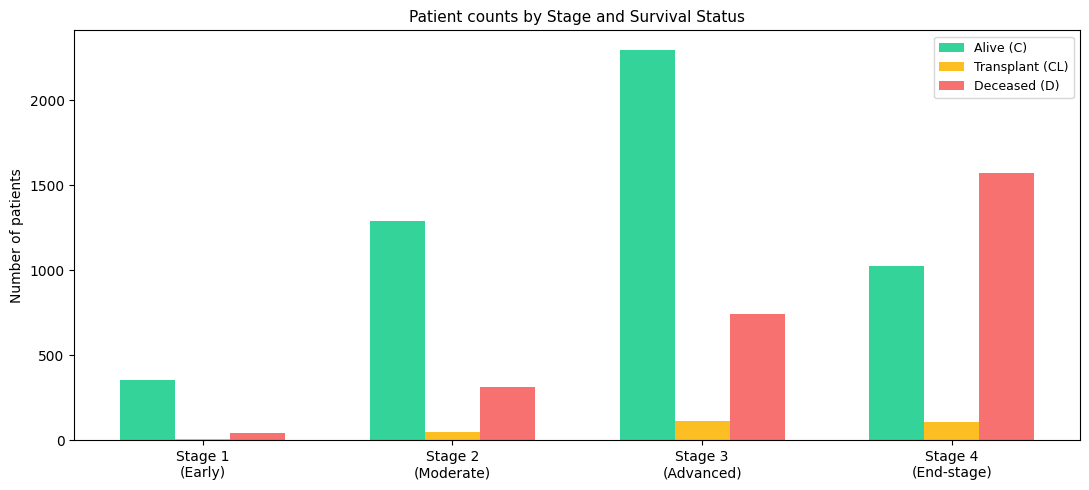

In [ ]:
stage_labels = {1: 'Early', 2: 'Moderate', 3: 'Advanced', 4: 'End-stage'}
color_map    = {'C': '#34d399', 'CL': '#fbbf24', 'D': '#f87171'}
label_map    = {'C': 'Alive (C)', 'CL': 'Transplant (CL)', 'D': 'Deceased (D)'}

cross_counts = pd.crosstab(train['Stage'], train['Status'])
col_order    = [c for c in ['C', 'CL', 'D'] if c in cross_counts.columns]
cross_counts = cross_counts[col_order]

fig, ax = plt.subplots(figsize=(11, 5))
x      = np.arange(len(cross_counts))
width  = 0.22
offsets = [-width, 0, width]

for col, offset in zip(col_order, offsets):
    ax.bar(x + offset, cross_counts[col].values,
           width=width, color=color_map[col],
           label=label_map[col], edgecolor='none')

ax.set_xticks(x)
ax.set_xticklabels([f"Stage {int(s)}\n({stage_labels[int(s)]})"
                    for s in cross_counts.index])
ax.set_ylabel('Number of patients')
ax.set_title('Patient counts by Stage and Survival Status', fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('outputs/01_counts_by_stage_status.png', dpi=130, bbox_inches='tight')
plt.show()
